In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn nltk

In [2]:
import re
import html
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")

print("All libraries imported successfully.")

All libraries imported successfully.


In [4]:
df = pd.read_csv("/content/IMDB Dataset.csv")




In [5]:

print("Dataset shape:", df.shape)

display(df.head())

Dataset shape: (50000, 2)


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [6]:
df.shape

(50000, 2)

In [9]:
df.columns

Index(['review', 'sentiment'], dtype='object')

In [11]:
df.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
49995,False
49996,False
49997,False
49998,False


In [12]:
df.duplicated().sum()

np.int64(418)

In [13]:
df.drop_duplicates()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive
...,...,...
49995,I thought this movie did a down right good job...,positive
49996,"Bad plot, bad dialogue, bad acting, idiotic di...",negative
49997,I am a Catholic taught in parochial elementary...,negative
49998,I'm going to have to disagree with the previou...,negative


In [50]:
df.head(10)

,review,sentiment,clean_review
0,One of the other reviewers has mentioned that ...,positive,one reviewer mentioned watching oz episode hoo...
1,A wonderful little production. <br /><br />The...,positive,wonderful little production filming technique ...
2,I thought this was a wonderful way to spend ti...,positive,thought wonderful way spend time hot summer we...
3,Basically there's a family where a little boy ...,negative,basically family little boy jake think zombie ...
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive,petter mattei love time money visually stunnin...
5,"Probably my all-time favorite movie, a story o...",positive,probably time favorite movie story selflessnes...
6,I sure would like to see a resurrection of a u...,positive,sure would like see resurrection dated seahunt...
7,"This show was an amazing, fresh & innovative i...",negative,show amazing fresh innovative idea first aired...
8,Encouraged by the positive comments about this...,negative,encouraged positive comment film looking forwa...
9,If you like original gut wrenching laughter yo...,positive,like original gut wrenching laughter like movi...


In [51]:
df.tail(10)

,review,sentiment,clean_review
49572,I got this one a few weeks ago and love it! It...,positive,got one week ago love modern light filled true...
49573,"Lame, lame, lame!!! A 90-minute cringe-fest th...",negative,lame lame lame minute cringe fest minute long ...
49574,John Garfield plays a Marine who is blinded by...,positive,john garfield play marine blinded grenade figh...
49575,Robert Colomb has two full-time jobs. He's kno...,negative,robert colomb two full time job known througho...
49576,This is your typical junk comedy.<br /><br />T...,negative,typical junk comedy almost no laugh no genuine...
49577,I thought this movie did a down right good job...,positive,thought movie right good job creative original...
49578,"Bad plot, bad dialogue, bad acting, idiotic di...",negative,bad plot bad dialogue bad acting idiotic direc...
49579,I am a Catholic taught in parochial elementary...,negative,catholic taught parochial elementary school nu...
49580,I'm going to have to disagree with the previou...,negative,going disagree previous comment side maltin on...
49581,No one expects the Star Trek movies to be high...,negative,no one expects star trek movie high art fan ex...


In [15]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nSentiment distribution:")
print(df["sentiment"].value_counts())

Column names:
['review', 'sentiment']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  object
dtypes: object(2)
memory usage: 781.4+ KB

Missing values:


,0
review,0
sentiment,0



Duplicate rows: 418

Sentiment distribution:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64


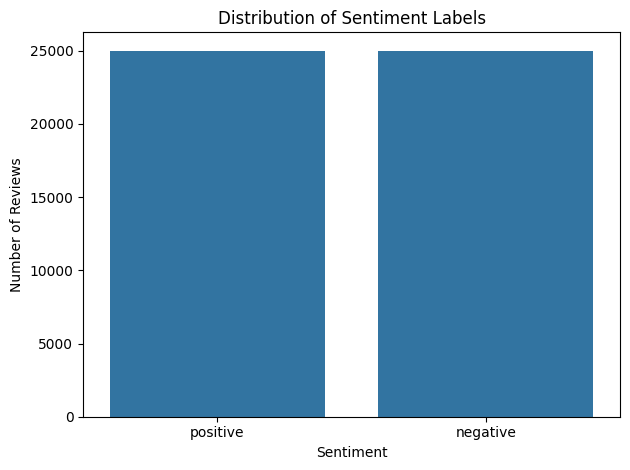

In [16]:
sns.countplot(data=df, x="sentiment")

plt.title("Distribution of Sentiment Labels")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

In [17]:
df = df.copy()

df["review"] = df["review"].fillna("").astype(str).str.strip()
df["sentiment"] = (
    df["sentiment"]
    .astype("string")
    .str.strip()
    .str.lower()
)

df = df[
    (df["review"] != "") &
    (df["sentiment"].isin(["positive", "negative"]))
].copy()

df = df.drop_duplicates(subset=["review", "sentiment"])

df = df.reset_index(drop=True)

print("Dataset shape after cleaning:", df.shape)
print(df["sentiment"].value_counts())

Dataset shape after cleaning: (49582, 2)
sentiment
positive    24884
negative    24698
Name: count, dtype: Int64


In [19]:
import nltk
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("punkt")

stop_words = set(stopwords.words("english"))

# Keep negation words because they can reverse sentiment.
stop_words -= {"no", "not", "nor", "never"}

lemmatizer = WordNetLemmatizer()

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


In [20]:
def preprocess_text(text):
    text = html.unescape(str(text))
    text = re.sub(r"<[^>]+>", " ", text)

    # Convert to lowercase
    text = text.lower()

    # Keep letters and whitespace
    text = re.sub(r"[^a-z\s]", " ", text)

    # Remove extra whitespace
    text = re.sub(r"\s+", " ", text).strip()

    # Tokenize
    tokens = word_tokenize(text)

    # Remove selected stopwords and lemmatize
    processed_tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word not in stop_words
    ]

    return " ".join(processed_tokens)

In [23]:
import nltk
nltk.download('punkt_tab')

example = "<p>The products were AMAZING, and I loved them!</p>"

print("Original text:")
print(example)

print("\nProcessed text:")
print(preprocess_text(example))

Original text:
<p>The products were AMAZING, and I loved them!</p>

Processed text:
product amazing loved


[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [24]:
df["clean_review"] = df["review"].apply(preprocess_text)

display(df[["review", "clean_review", "sentiment"]].head())

,review,clean_review,sentiment
0,One of the other reviewers has mentioned that ...,one reviewer mentioned watching oz episode hoo...,positive
1,A wonderful little production. <br /><br />The...,wonderful little production filming technique ...,positive
2,I thought this was a wonderful way to spend ti...,thought wonderful way spend time hot summer we...,positive
3,Basically there's a family where a little boy ...,basically family little boy jake think zombie ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",petter mattei love time money visually stunnin...,positive


In [25]:
X = df["clean_review"]
y = df["sentiment"]

print("Input text shape:", X.shape)
print("Target shape:", y.shape)

print("\nExample input:")
print(X.iloc[0])

print("\nExample target:")
print(y.iloc[0])

Input text shape: (49582,)
Target shape: (49582,)

Example input:
one reviewer mentioned watching oz episode hooked right exactly happened first thing struck oz brutality unflinching scene violence set right word go trust not show faint hearted timid show pull no punch regard drug sex violence hardcore classic use word called oz nickname given oswald maximum security state penitentary focus mainly emerald city experimental section prison cell glass front face inwards privacy not high agenda em city home many aryan muslim gangsta latino christian italian irish scuffle death stare dodgy dealing shady agreement never far away would say main appeal show due fact go show dare forget pretty picture painted mainstream audience forget charm forget romance oz mess around first episode ever saw struck nasty surreal say ready watched developed taste oz got accustomed high level graphic violence not violence injustice crooked guard sold nickel inmate kill order get away well mannered middle class 

In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training reviews:", len(X_train))
print("Testing reviews:", len(X_test))

print("\nTraining sentiment distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting sentiment distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training reviews: 39665
Testing reviews: 9917

Training sentiment distribution:
sentiment
positive    0.502
negative    0.498
Name: proportion, dtype: Float64

Testing sentiment distribution:
sentiment
positive    0.502
negative    0.498
Name: proportion, dtype: Float64


In [27]:
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 1)
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))

Training TF-IDF shape: (39665, 5000)
Testing TF-IDF shape: (9917, 5000)
Vocabulary size: 5000


In [28]:
feature_names = tfidf.get_feature_names_out()

tfidf_preview = pd.DataFrame(
    X_train_tfidf[:5, :10].toarray(),
    columns=feature_names[:10]
)

display(tfidf_preview)

,aaron,abandoned,abc,ability,able,abrupt,absence,absent,absolute,absolutely
0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.000000
1,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.000000
2,0.0,0.0,0.0,0.0,0.051236,0.0,0.0,0.0,0.0,0.000000
3,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.091736
4,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.000000


In [29]:
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

print("Multinomial Naive Bayes training completed.")

Multinomial Naive Bayes training completed.


In [30]:

nb_predictions = nb_model.predict(X_test_tfidf)

print("First 10 predictions:")
print(nb_predictions[:10])

print("\nFirst 10 actual labels:")
print(y_test.iloc[:10].to_list())

First 10 predictions:
['negative' 'positive' 'positive' 'negative' 'negative' 'positive'
 'negative' 'negative' 'positive' 'negative']

First 10 actual labels:
['negative', 'positive', 'positive', 'negative', 'negative', 'positive', 'negative', 'negative', 'positive', 'negative']


In [31]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train_tfidf, y_train)

print("Logistic Regression training completed.")

Logistic Regression training completed.


In [32]:
lr_predictions = lr_model.predict(X_test_tfidf)

print("First 10 Logistic Regression predictions:")
print(lr_predictions[:10])

First 10 Logistic Regression predictions:
['negative' 'positive' 'positive' 'negative' 'negative' 'positive'
 'negative' 'negative' 'positive' 'negative']


In [33]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

def evaluate_model(model_name, y_true, y_pred):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred,
            pos_label="positive",
            zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred,
            pos_label="positive",
            zero_division=0
        ),
        "F1-score": f1_score(
            y_true, y_pred,
            pos_label="positive",
            zero_division=0
        )
    }

results = pd.DataFrame([
    evaluate_model("Multinomial Naive Bayes", y_test, nb_predictions),
    evaluate_model("Logistic Regression", y_test, lr_predictions)
])

display(results.round(4))

,Model,Accuracy,Precision,Recall,F1-score
0,Multinomial Naive Bayes,0.8563,0.8511,0.865,0.8580
1,Logistic Regression,0.8897,0.8803,0.903,0.8915


In [34]:
print("NAIVE BAYES CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    nb_predictions,
    zero_division=0
))

print("LOGISTIC REGRESSION CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    lr_predictions,
    zero_division=0
))

NAIVE BAYES CLASSIFICATION REPORT
              precision    recall  f1-score   support

    negative       0.86      0.85      0.85      4940
    positive       0.85      0.86      0.86      4977

    accuracy                           0.86      9917
   macro avg       0.86      0.86      0.86      9917
weighted avg       0.86      0.86      0.86      9917

LOGISTIC REGRESSION CLASSIFICATION REPORT
              precision    recall  f1-score   support

    negative       0.90      0.88      0.89      4940
    positive       0.88      0.90      0.89      4977

    accuracy                           0.89      9917
   macro avg       0.89      0.89      0.89      9917
weighted avg       0.89      0.89      0.89      9917



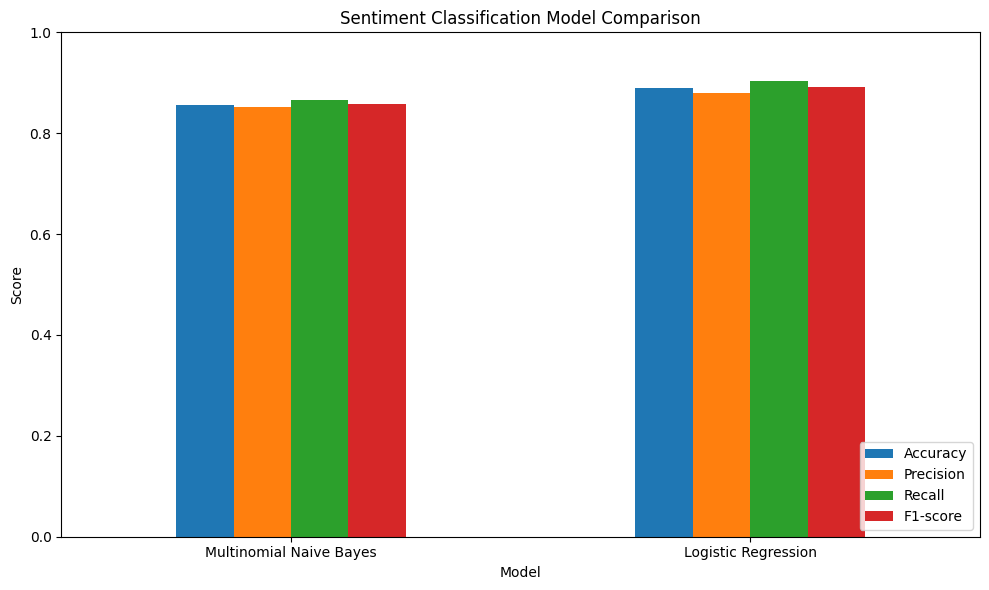

In [35]:
results_plot = results.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-score"]
]

results_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Sentiment Classification Model Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

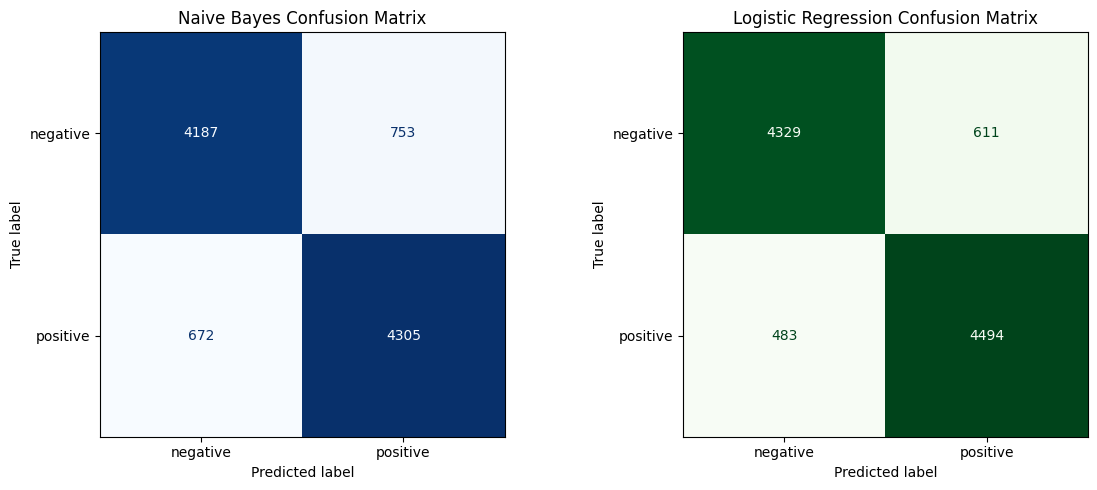

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    nb_predictions,
    labels=["negative", "positive"],
    cmap="Blues",
    ax=axes[0],
    colorbar=False
)
axes[0].set_title("Naive Bayes Confusion Matrix")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    lr_predictions,
    labels=["negative", "positive"],
    cmap="Greens",
    ax=axes[1],
    colorbar=False
)
axes[1].set_title("Logistic Regression Confusion Matrix")

plt.tight_layout()
plt.show()

In [43]:
def predict_sentiment(review, model="Logistic Regression"):
    cleaned_review = preprocess_text(review)

    if not cleaned_review.strip():
        return {
            "review": review,
            "predicted_sentiment": "Unable to classify empty text",
            "confidence": None
        }

    review_tfidf = tfidf.transform([cleaned_review])

    if model == "Naive Bayes":
        classifier = nb_model
    else:
        classifier = lr_model

    prediction = classifier.predict(review_tfidf)[0]
    probabilities = classifier.predict_proba(review_tfidf)[0]

    class_names = list(classifier.classes_)
    confidence = probabilities[class_names.index(prediction)]

    return {
        "review": review,
        "cleaned_review": cleaned_review,
        "predicted_sentiment": prediction,
        "confidence": round(float(confidence), 4)
    }

In [44]:
print(predict_sentiment(
    "This product is excellent and I love it!"
))

print(predict_sentiment(
    "The quality is terrible and I hate it."
))

print(predict_sentiment(
    "I did not like this product at all."
))

{'review': 'This product is excellent and I love it!', 'cleaned_review': 'product excellent love', 'predicted_sentiment': 'positive', 'confidence': 0.9901}
{'review': 'The quality is terrible and I hate it.', 'cleaned_review': 'quality terrible hate', 'predicted_sentiment': 'negative', 'confidence': 0.9626}
{'review': 'I did not like this product at all.', 'cleaned_review': 'not like product', 'predicted_sentiment': 'negative', 'confidence': 0.6978}


In [45]:

print(
    predict_sentiment(
        "The service was wonderful.",
        model="Naive Bayes"
    )
)

{'review': 'The service was wonderful.', 'cleaned_review': 'service wonderful', 'predicted_sentiment': np.str_('positive'), 'confidence': 0.7317}


In [49]:
while True:
    review = input(
        "Enter a review (or type 'exit' to stop): "
    )

    if review.strip().lower() == "exit":
        print("Testing completed.")
        break

    result = predict_sentiment(review)

    print("Predicted sentiment:",
          result["predicted_sentiment"])

    print("Estimated confidence:",
          result["confidence"])

Enter a review (or type 'exit' to stop): exit
Testing completed.


In [47]:
results.to_csv(
    "sentiment_model_comparison.csv",
    index=False
)

print("Model comparison saved successfully.")

Model comparison saved successfully.


In [48]:
import joblib

joblib.dump(lr_model, "sentiment_model.pkl")
joblib.dump(tfidf, "tfidf_vectorizer.pkl")

print("Model and vectorizer saved successfully.")

Model and vectorizer saved successfully.
